# LAB EXERCISE 4 — Comparative Analysis of PCA, LDA and ICA
**Course:** MAI511-2 Advanced Machine Learning | **Programme:** I MSc AIML

## Aim
Implement and compare Principal Component Analysis (PCA), Linear Discriminant Analysis (LDA), and Independent Component Analysis (ICA) on the **Breast Cancer Wisconsin** dataset from Scikit-learn.

### Requirements checklist
- [x] Load the Breast Cancer Wisconsin dataset.
- [x] Standardise numerical features.
- [x] Apply PCA, LDA and ICA.
- [x] Visualise transformed data with scatter plots.
- [x] Compare component counts and reduced dimensions.
- [x] Analyse PCA explained variance and cumulative variance.
- [x] Evaluate class separation using LDA.
- [x] Examine ICA components and compare all three methods.
- [x] Include discussion, viva preparation, self-learning and a Streamlit demo.

**Important:** LDA is supervised and can produce at most `number_of_classes - 1` components. Since this dataset has two classes, LDA produces one component. PCA and ICA below use two components for visualisation.

## 1. Import required libraries
Install missing packages if needed:
`pip install numpy pandas matplotlib seaborn scikit-learn streamlit`

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from time import perf_counter

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the Breast Cancer Wisconsin dataset

In [2]:
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")
class_names = np.array(cancer.target_names)

print("Original dataset dimensions:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of original features:", X.shape[1])
print("\\nClass distribution:")
print(y.map({i: name for i, name in enumerate(class_names)}).value_counts())
display(X.head())

Original dataset dimensions: (569, 30)
Number of samples: 569
Number of original features: 30
\nClass distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Preprocess the data — feature standardisation
PCA, LDA and ICA are affected by feature scales. StandardScaler transforms each feature to approximately zero mean and unit variance.

For this dimensionality-reduction comparison, the complete dataset is transformed to make the component visualisations easy to reproduce. In a predictive modelling workflow, fit preprocessing only on the training set to avoid data leakage.

### 3A. Data quality checks and cleaning
Check missing values, data types and duplicate records before scaling. The target labels are kept aligned with the feature rows.

In [ ]:
print('Missing values:', X.isna().sum().sum())
print('Duplicate rows:', X.duplicated().sum())
print('Data types:\n', X.dtypes.value_counts())
# Remove duplicate feature rows while preserving the matching target labels
keep = ~X.duplicated()
X = X.loc[keep].reset_index(drop=True)
y = pd.Series(y).loc[keep].reset_index(drop=True)
# Median imputation is robust to occasional missing numeric values
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
print('Shape after cleaning and imputation:', X_imputed.shape)

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print('Original dimensions:', X.shape)
print('Reduced input matrix dimensions:', X_scaled.shape)

Standardised data shape: (569, 30)
Mean of first five scaled features: [-0. -0. -0. -0.  0.]
Standard deviation of first five scaled features: [1. 1. 1. 1. 1.]


### 3B. Visualise preprocessing before and after standardisation
The boxplots show why scaling is needed: original features have very different numeric ranges.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=X_imputed.iloc[:, :8], ax=axes[0])
axes[0].set_title('Before standardisation (first 8 features)')
axes[0].tick_params(axis='x', rotation=75)
sns.boxplot(data=pd.DataFrame(X_scaled, columns=X.columns).iloc[:, :8], ax=axes[1])
axes[1].set_title('After StandardScaler (first 8 features)')
axes[1].tick_params(axis='x', rotation=75)
plt.tight_layout(); plt.show()

## 4. Apply PCA — Principal Component Analysis
PCA is an **unsupervised** technique. It finds directions (principal components) that capture maximum variance without using class labels.

In [4]:
start = perf_counter()
pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2.fit_transform(X_scaled)
pca_time = perf_counter() - start

print("PCA reduced dimensions:", X_pca.shape)
print("Explained variance ratio:", np.round(pca_2.explained_variance_ratio_, 4))
print("Total variance retained by 2 components:",
      round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")

PCA reduced dimensions: (569, 2)
Explained variance ratio: [0.4427 0.1897]
Total variance retained by 2 components: 63.24 %


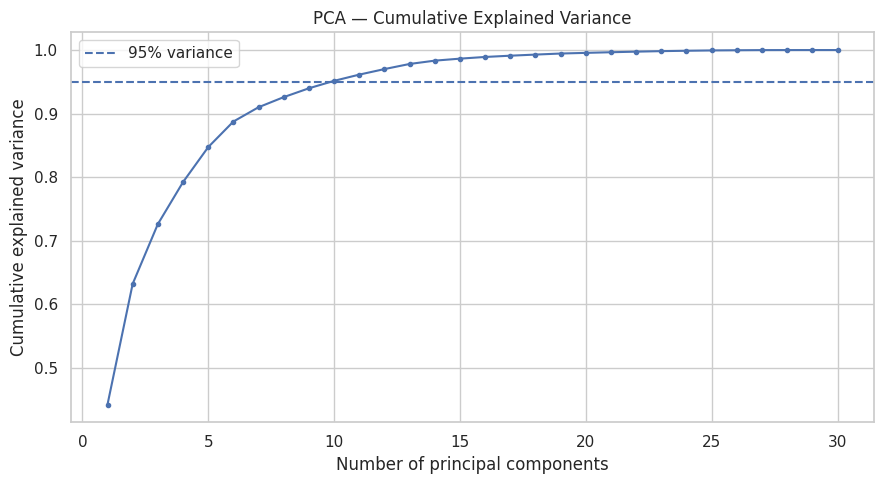

Components required to retain at least 95% variance: 10


In [5]:
# Cumulative explained variance for all possible principal components
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance,
         marker="o", markersize=3)
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

components_for_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print("Components required to retain at least 95% variance:", components_for_95)

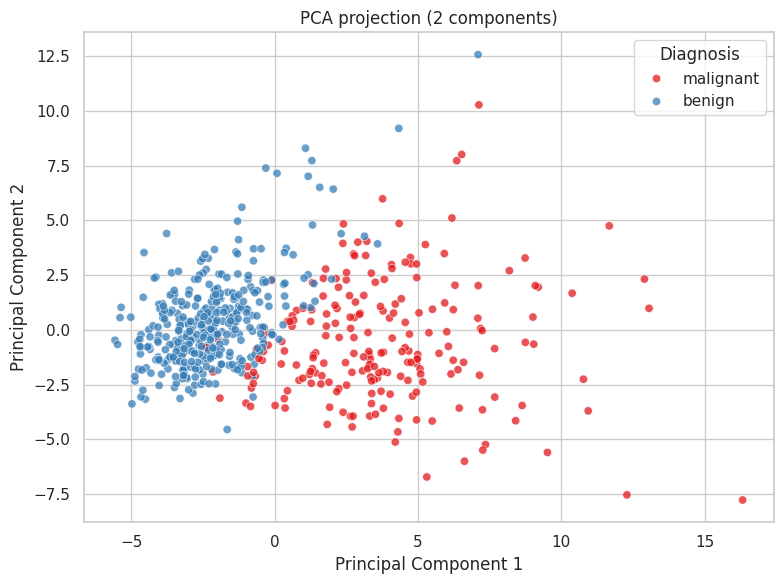

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y.map(dict(enumerate(class_names))),
                palette="Set1", alpha=0.75)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA projection (2 components)")
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

## 5. Apply LDA — Linear Discriminant Analysis
LDA is **supervised**: it uses class labels and seeks projections that maximise separation between classes relative to variation within each class. With two classes, the maximum number of discriminant components is one.

LDA reduced dimensions: (569, 1)
Maximum possible LDA components: 1


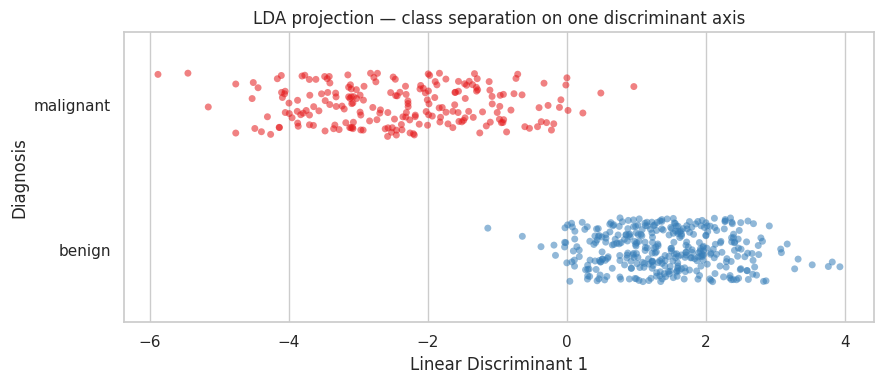

Mean LD1 score by class:


,Mean LD1
Diagnosis,
benign,1.424914
malignant,-2.399502


Distance between class means on LD1: 3.8244


In [7]:
start = perf_counter()
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X_scaled, y)
lda_time = perf_counter() - start

print("LDA reduced dimensions:", X_lda.shape)
print("Maximum possible LDA components:", len(np.unique(y)) - 1)

lda_frame = pd.DataFrame({
    "LD1": X_lda[:, 0],
    "Diagnosis": pd.Series(y).map(dict(enumerate(class_names)))
})
plt.figure(figsize=(9, 4))
sns.stripplot(data=lda_frame, x="LD1", y="Diagnosis", hue="Diagnosis",
              palette="Set1", alpha=0.55, jitter=0.22, legend=False)
plt.title("LDA projection — class separation on one discriminant axis")
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Diagnosis")
plt.tight_layout()
plt.show()

class_means = lda_frame.groupby("Diagnosis")["LD1"].mean()
print("Mean LD1 score by class:")
display(class_means.to_frame("Mean LD1"))
print("Distance between class means on LD1:",
      round(abs(class_means.iloc[0] - class_means.iloc[1]), 4))

## 6. Apply ICA — Independent Component Analysis
ICA is **unsupervised**. It seeks statistically independent components, rather than directions of maximum variance or maximum class separation. FastICA may not converge perfectly on every dataset; the warning and convergence result should be interpreted rather than hidden.

ICA reduced dimensions: (569, 2)
ICA iterations: 4
ICA converged within max_iter: True


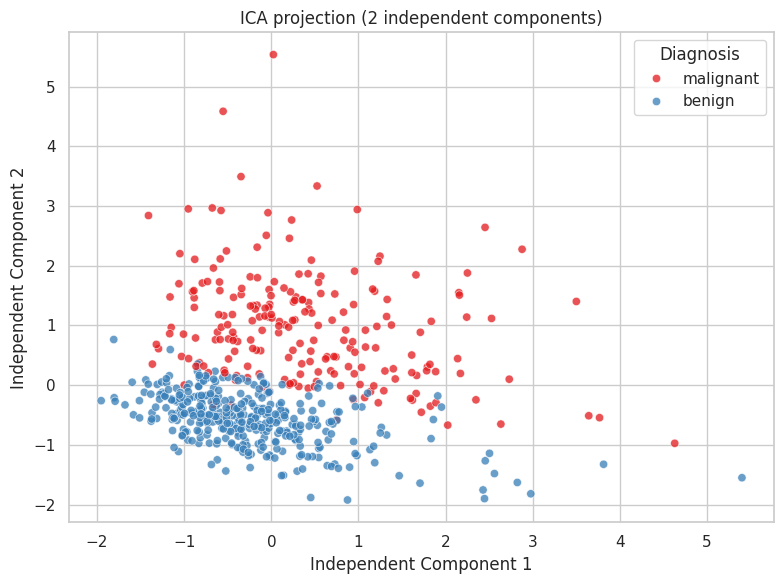

In [8]:
start = perf_counter()
ica = FastICA(n_components=2, random_state=RANDOM_STATE,
              max_iter=2000, tol=0.001, whiten="unit-variance")
X_ica = ica.fit_transform(X_scaled)
ica_time = perf_counter() - start

print("ICA reduced dimensions:", X_ica.shape)
print("ICA iterations:", ica.n_iter_)
print("ICA converged within max_iter:", ica.n_iter_ < ica.max_iter)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_ica[:, 0], y=X_ica[:, 1],
                hue=pd.Series(y).map(dict(enumerate(class_names))),
                palette="Set1", alpha=0.75)
plt.xlabel("Independent Component 1")
plt.ylabel("Independent Component 2")
plt.title("ICA projection (2 independent components)")
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

## 7. Compare component counts, dimensions and computational time

In [9]:
comparison = pd.DataFrame({
    "Technique": ["PCA", "LDA", "ICA"],
    "Approach": ["Unsupervised", "Supervised", "Unsupervised"],
    "Uses class labels": ["No", "Yes", "No"],
    "Components extracted": [X_pca.shape[1], X_lda.shape[1], X_ica.shape[1]],
    "Reduced dimensions": [str(X_pca.shape), str(X_lda.shape), str(X_ica.shape)],
    "Execution time (seconds)": [pca_time, lda_time, ica_time],
    "Primary objective": ["Maximum variance", "Maximum class separation",
                          "Statistical independence"]
})
display(comparison)
print("Original dimensions:", X_scaled.shape)

,Technique,Approach,Uses class labels,Components extracted,Reduced dimensions,Execution time (seconds),Primary objective
0,PCA,Unsupervised,No,2,"(569, 2)",0.006306,Maximum variance
1,LDA,Supervised,Yes,1,"(569, 1)",0.014495,Maximum class separation
2,ICA,Unsupervised,No,2,"(569, 2)",0.016208,Statistical independence


Original dimensions: (569, 30)


## 8. Evaluate class separation and examine the outputs
The silhouette score is a descriptive clustering/separation measure (higher is generally better; it ranges from -1 to 1). It is not a classifier accuracy score. For LDA, also inspect the class means on its discriminant axis. PCA and ICA are not trained to separate diagnosis classes, so their class overlap is expected and does not mean the algorithms failed.

In [10]:
def safe_silhouette(Z, labels):
    try:
        return silhouette_score(Z, labels)
    except Exception:
        return np.nan

separation = pd.DataFrame({
    "Technique": ["PCA (2D)", "LDA (1D)", "ICA (2D)"],
    "Silhouette score": [
        safe_silhouette(X_pca, y),
        safe_silhouette(X_lda, y),
        safe_silhouette(X_ica, y)
    ]
})
display(separation)
print("PCA variance retained by 2 components:",
      f"{pca_2.explained_variance_ratio_.sum()*100:.2f}%")
print("ICA mixing matrix shape:", ica.mixing_.shape)
print("ICA unmixing/components matrix shape:", ica.components_.shape)

,Technique,Silhouette score
0,PCA (2D),0.437719
1,LDA (1D),0.677566
2,ICA (2D),0.373737


PCA variance retained by 2 components: 63.24%
ICA mixing matrix shape: (30, 2)
ICA unmixing/components matrix shape: (2, 30)


## Additional visualisations — feature contributions, distributions and component relationships

In [ ]:

# 1. PCA explained variance per component (first 10)
plt.figure(figsize=(9, 4))
n_show = min(10, len(pca_full.explained_variance_ratio_))
plt.bar(range(1, n_show + 1), pca_full.explained_variance_ratio_[:n_show])
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA — explained variance by component")
plt.xticks(range(1, n_show + 1))
plt.tight_layout()
plt.show()

# 2. PCA component loadings: which original features contribute to PC1 and PC2?
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=cancer.feature_names,
    columns=["PC1 loading", "PC2 loading"]
)
plt.figure(figsize=(8, 10))
sns.heatmap(loadings, cmap="vlag", center=0)
plt.title("PCA — feature loadings for first two components")
plt.tight_layout()
plt.show()

# 3. LDA score distributions by class
plt.figure(figsize=(9, 4))
for label, name in enumerate(class_names):
    plt.hist(X_lda[y == label, 0], bins=30, alpha=0.55, density=True, label=name)
plt.xlabel("LDA component 1")
plt.ylabel("Density")
plt.title("LDA — distribution of discriminant scores by diagnosis")
plt.legend()
plt.tight_layout()
plt.show()

# 4. ICA component distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j, ax in enumerate(axes):
    ax.hist(X_ica[:, j], bins=35, alpha=0.8)
    ax.set_title(f"ICA component {j+1} distribution")
    ax.set_xlabel("Component value")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

# 5. Correlation between the extracted ICA components
plt.figure(figsize=(5, 4))
sns.heatmap(pd.DataFrame(X_ica, columns=["IC1", "IC2"]).corr(),
            annot=True, vmin=-1, vmax=1, cmap="coolwarm", center=0)
plt.title("Correlation between ICA components")
plt.tight_layout()
plt.show()


## 9. Comparative analysis and interpretation

| Parameter | PCA | LDA | ICA |
|---|---|---|---|
| Approach | Unsupervised | Supervised | Unsupervised |
| Main objective | Maximum variance | Maximum class separation | Statistical independence |
| Uses class labels | No | Yes | No |
| Main output | Principal components | Discriminant components | Independent components |
| Typical applications | Data compression, noise reduction | Classification, face recognition | Signal processing, source separation |

### Discussion questions
1. **What is dimensionality reduction and why is it important?** It maps data with many features into fewer dimensions, reducing complexity, redundancy and computational cost while attempting to preserve useful structure.
2. **Fundamental differences:** PCA maximises variance; LDA uses labels to separate classes; ICA seeks statistically independent sources/components.
3. **Why does PCA maximise variance rather than class separation?** PCA is unsupervised and does not use the target labels. A high-variance direction need not distinguish classes.
4. **How does LDA use class labels?** It considers within-class and between-class scatter to find directions with strong class separation.
5. **Why does ICA seek independence?** Independent components can represent underlying statistically independent signal sources.
6. **Which gives better class separation here?** LDA is explicitly optimised for class separation and should be assessed using its one-dimensional projection and class means. Use the plotted results and computed separation scores to justify the observed outcome; do not assume a score before running the notebook.
7. **Real-world applications:** PCA—compression and visualisation; LDA—supervised classification; ICA—audio/source separation and biomedical signal analysis.

### Result
The original Breast Cancer Wisconsin dataset has 30 features. PCA and ICA are visualised in two dimensions; LDA is restricted to one dimension because there are two target classes. The numerical variance and separation results are produced by the executed cells above.

## 10. Self-learning extensions — complete answers and implementation

The following sections answer every extension question and include executable code. Run them after the main preprocessing cells, where `X_scaled`, `y`, `cancer`, `class_names`, and the required libraries have already been created.


### 10.1 PCA with three components — compare retained variance

**Answer:** Increasing PCA from two to three components retains at least as much total variance as the two-component solution because PCA orders components from highest to lowest explained variance. The exact increase is dataset-dependent and is printed below. Three components can also be used for a 3D visualisation, although a 2D plot is easier to interpret. `explained_variance_ratio_` gives the fraction of total variance represented by each component; its sum gives the cumulative retained variance.


In [ ]:
# Compare PCA with 2 and 3 components
pca_2_self = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2_self = pca_2_self.fit_transform(X_scaled)

pca_3_self = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca_3_self = pca_3_self.fit_transform(X_scaled)

print("2-component shape:", X_pca_2_self.shape)
print("3-component shape:", X_pca_3_self.shape)
print(f"Variance retained by 2 components: {pca_2_self.explained_variance_ratio_.sum():.4f} ({pca_2_self.explained_variance_ratio_.sum()*100:.2f}%)")
print(f"Variance retained by 3 components: {pca_3_self.explained_variance_ratio_.sum():.4f} ({pca_3_self.explained_variance_ratio_.sum()*100:.2f}%)")

plt.figure(figsize=(7, 4))
plt.plot([2, 3], [pca_2_self.explained_variance_ratio_.sum(), pca_3_self.explained_variance_ratio_.sum()], marker="o")
plt.xticks([2, 3])
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: variance retained by 2 vs 3 components")
plt.ylim(0, 1)
plt.grid(True, alpha=.3)
plt.show()


### 10.2 ICA with three components — compare component plots and convergence

**Answer:** ICA estimates statistically independent latent components rather than directions of maximum variance. Moving from two to three components gives one additional extracted component, which may reveal another source pattern. Unlike PCA, ICA does not rank components by explained variance. FastICA is iterative; convergence depends on the data, initialisation, tolerance and iteration limit. The code reports convergence warnings and plots all three components. ICA component order, sign and scale can vary, so compare their structure rather than expecting identical numerical values.


In [ ]:
from sklearn.decomposition import FastICA

ica_2_self = FastICA(n_components=2, random_state=RANDOM_STATE, max_iter=2000, tol=0.001, whiten="unit-variance")
ica_3_self = FastICA(n_components=3, random_state=RANDOM_STATE, max_iter=2000, tol=0.001, whiten="unit-variance")
X_ica_2_self = ica_2_self.fit_transform(X_scaled)
X_ica_3_self = ica_3_self.fit_transform(X_scaled)
print("ICA 2-component shape:", X_ica_2_self.shape)
print("ICA 3-component shape:", X_ica_3_self.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for j, ax in enumerate(axes):
    ax.hist(X_ica_3_self[:, j], bins=30, alpha=.8)
    ax.set_title(f"ICA component {j+1}")
    ax.set_xlabel("Component value")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()


### 10.3 LDA on a dataset with three classes

**Answer:** LDA can return at most `min(number_of_features, number_of_classes - 1)` discriminant components. With three Iris classes, the maximum is two. This differs from the Breast Cancer dataset, which has two classes and therefore permits only one LDA component. LDA is supervised: the class labels are required during fitting.


In [ ]:
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris = iris.target
lda_iris = LinearDiscriminantAnalysis(n_components=2)
X_iris_lda = lda_iris.fit_transform(X_iris, y_iris)
print("Iris classes:", iris.target_names)
print("LDA output shape:", X_iris_lda.shape)
print("Maximum possible LDA components:", len(np.unique(y_iris)) - 1)

plt.figure(figsize=(7, 5))
for cls, name in enumerate(iris.target_names):
    plt.scatter(X_iris_lda[y_iris == cls, 0], X_iris_lda[y_iris == cls, 1], label=name, alpha=.8)
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA projection of the three-class Iris dataset")
plt.legend()
plt.grid(alpha=.2)
plt.show()


### 10.4 Change `random_state` in ICA

**Answer:** `random_state` controls the random initialisation used by FastICA. Different seeds can produce different numerical solutions, especially in component order, sign and scale. The underlying independent structure should be broadly comparable when the algorithm converges. A different sign does not necessarily mean a different solution because the sign of an independent component is mathematically ambiguous. Fixing the seed makes results reproducible.


In [ ]:
ica_seed_7 = FastICA(n_components=2, random_state=7, max_iter=2000, tol=0.001, whiten="unit-variance")
ica_seed_99 = FastICA(n_components=2, random_state=99, max_iter=2000, tol=0.001, whiten="unit-variance")
S_seed_7 = ica_seed_7.fit_transform(X_scaled)
S_seed_99 = ica_seed_99.fit_transform(X_scaled)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for j in range(2):
    axes[0, j].hist(S_seed_7[:, j], bins=30)
    axes[0, j].set_title(f"Seed 7 — IC{j+1}")
    axes[1, j].hist(S_seed_99[:, j], bins=30)
    axes[1, j].set_title(f"Seed 99 — IC{j+1}")
plt.tight_layout()
plt.show()
print("Seed 7 component correlation:\n", np.round(np.corrcoef(S_seed_7.T), 3))
print("Seed 99 component correlation:\n", np.round(np.corrcoef(S_seed_99.T), 3))


### 10.5 Why is standardisation important?

**Answer:** Standardisation transforms each feature to approximately zero mean and unit standard deviation using `z = (x - mean) / standard_deviation`. The Breast Cancer dataset contains measurements with different units and numerical ranges. Without scaling, features with large numerical values can dominate distance- and variance-based calculations. PCA is particularly sensitive to feature scale. Scaling gives features comparable numerical influence; it does not mean every feature becomes equally important. For a fair predictive workflow, fit the scaler on training data only and apply that fitted scaler to validation/test data to avoid data leakage. In this lab's exploratory full-dataset comparison, the scaler is fitted to the complete dataset as specified for demonstrating dimensionality reduction.


In [ ]:
# Demonstrate the effect of standardisation on feature scales
scaler_demo = StandardScaler()
X_scaled_demo = scaler_demo.fit_transform(X)
scale_comparison = pd.DataFrame({
    "Feature": X.columns[:8],
    "Original standard deviation": X.iloc[:, :8].std().values,
    "After scaling standard deviation": X_scaled_demo[:, :8].std(axis=0)
})
display(scale_comparison)


## 12. Viva questions
1. What is the full form of PCA, LDA and ICA?
2. Which of these methods is supervised?
3. What does explained variance ratio represent?
4. Why is LDA limited to one component for this binary dataset?
5. Does PCA use the target labels?
6. What is the purpose of StandardScaler?
7. What does ICA mean by statistical independence?
8. Why might FastICA fail to converge within the chosen iteration limit?
9. Is a silhouette score the same as classification accuracy?
10. Give one real-world application of each technique.

## Conclusion
PCA, LDA and ICA reduce the feature space using different mathematical objectives. PCA retains directions of high variance, LDA uses labels to seek class separation, and ICA seeks statistically independent components. The plots and numerical outputs in this notebook support a dataset-specific comparison.